In [25]:
import os
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.17.0


In [2]:
import os
dataset_path = 'garbage-classification/Garbage classification/Garbage classification'
contents = os.listdir(dataset_path)
print(f"Contents of Garbage classification: {contents}")
for item in contents:
    item_path = os.path.join(dataset_path, item)
    if os.path.isdir(item_path):
        sub_contents = os.listdir(item_path)
        print(f"  {item} is a folder with {len(sub_contents)} images: {sub_contents[:3]}")
    else:
        print(f"  {item} is a file")

Contents of Garbage classification: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
  cardboard is a folder with 403 images: ['cardboard1.jpg', 'cardboard10.jpg', 'cardboard100.jpg']
  glass is a folder with 501 images: ['glass1.jpg', 'glass10.jpg', 'glass100.jpg']
  metal is a folder with 410 images: ['metal1.jpg', 'metal10.jpg', 'metal100.jpg']
  paper is a folder with 594 images: ['paper1.jpg', 'paper10.jpg', 'paper100.jpg']
  plastic is a folder with 482 images: ['plastic1.jpg', 'plastic10.jpg', 'plastic100.jpg']
  trash is a folder with 137 images: ['trash1.jpg', 'trash10.jpg', 'trash100.jpg']


In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32 

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.25,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


In [4]:
train_generator = train_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

validation_generator = val_datagen.flow_from_directory(
    dataset_path,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

num_classes = len(train_generator.class_indices)
print(f"✓ Classes: {train_generator.class_indices}")
print(f"✓ Total classes: {num_classes}")

Found 2527 images belonging to 6 classes.
Found 2527 images belonging to 6 classes.
✓ Classes: {'cardboard': 0, 'glass': 1, 'metal': 2, 'paper': 3, 'plastic': 4, 'trash': 5}
✓ Total classes: 6


In [5]:
base_model_res = ResNet50(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model_res.trainable = False  # freeze backbone

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


In [6]:
resnet_model = models.Sequential([
    base_model_res,
    layers.GlobalAveragePooling2D(),

    layers.BatchNormalization(),

    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),

    layers.Dense(64, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),

    layers.Dense(num_classes, activation='softmax')
])

In [7]:
resnet_model.compile(
    optimizer=Adam(learning_rate=3e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("✅ ResNet50 model compiled")
print(f"Total parameters: {resnet_model.count_params():,}")

✅ ResNet50 model compiled
Total parameters: 24,138,566


In [8]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

print("🚀 Training ResNet50 (head only)...")

history_resnet = resnet_model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=15,
    callbacks=[early_stop]
)

print("✅ ResNet50 head-only training completed")

🚀 Training ResNet50 (head only)...
Epoch 1/15


c:\Users\atharva\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


79/79 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.3986 - loss: 1.8531 - val_accuracy: 0.7946 - val_loss: 0.6263
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 96s 1s/step - accuracy: 0.6782 - loss: 0.9249 - val_accuracy: 0.8465 - val_loss: 0.4594
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.7115 - loss: 0.7951 - val_accuracy: 0.8801 - val_loss: 0.3650
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.7587 - loss: 0.7100 - val_accuracy: 0.9042 - val_loss: 0.3033
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.7848 - loss: 0.6494 - val_accuracy: 0.9149 - val_loss: 0.2657
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 97s 1s/step - accuracy: 0.8252 - loss: 0.5285 - val_accuracy: 0.9201 - val_loss: 0.2414
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 98s 1s/step - accuracy: 0.8232 - loss: 0.5286 - val_accuracy: 0.9244 - val_loss: 0.2210
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 167s 2s/step - accuracy: 0.8307 - loss: 0.5024 - val_accuracy: 0.9311 - val_loss: 0.2008
E

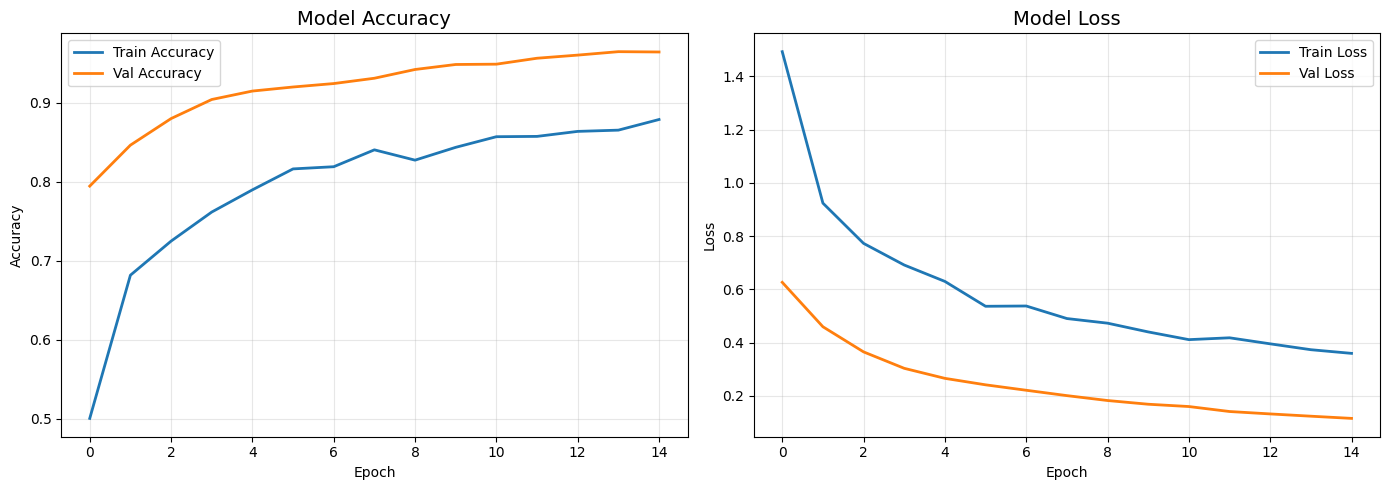


📊 Final Results:
   Train Accuracy: 0.8789
   Val Accuracy: 0.9644


In [26]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_resnet.history['accuracy'], label='Train Accuracy', linewidth=2)
plt.plot(history_resnet.history['val_accuracy'], label='Val Accuracy', linewidth=2)
plt.title('Model Accuracy', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_resnet.history['loss'], label='Train Loss', linewidth=2)
plt.plot(history_resnet.history['val_loss'], label='Val Loss', linewidth=2)
plt.title('Model Loss', fontsize=14)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# แสดงผล accuracy สุดท้าย
print(f"\n📊 Final Results:")
print(f"   Train Accuracy: {history_resnet.history['accuracy'][-1]:.4f}") 
print(f"   Val Accuracy: {history_resnet.history['val_accuracy'][-1]:.4f}") 

In [11]:
resnet_model.save("models/resnet50_head_only.keras")
print("✅ ResNet50 model saved in Keras format")

✅ ResNet50 model saved in Keras format


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

In [13]:
from tensorflow.keras.models import load_model

resnet_model = load_model("models/resnet50_head_only.keras")
print("✅ ResNet50 model loaded")

✅ ResNet50 model loaded


In [14]:
# Predict probabilities
y_pred_probs = resnet_model.predict(validation_generator)

# Convert probabilities → class labels
y_pred = np.argmax(y_pred_probs, axis=1)

# True labels
y_true = validation_generator.classes

class_names = list(validation_generator.class_indices.keys())

79/79 ━━━━━━━━━━━━━━━━━━━━ 49s 604ms/step


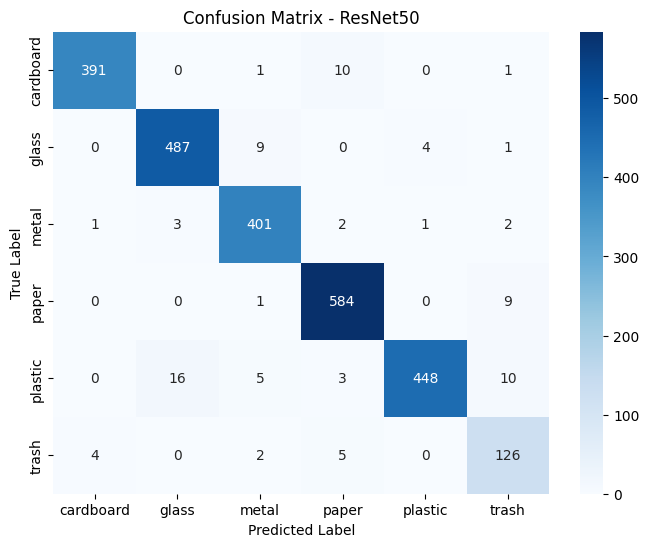

In [15]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - ResNet50")
plt.show()

“The confusion matrix shows that most classes are correctly classified, with very few misclassifications occurring between visually similar garbage categories.”

In [16]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print("📊 Classification Report:\n")
print(report)

📊 Classification Report:

              precision    recall  f1-score   support

   cardboard       0.99      0.97      0.98       403
       glass       0.96      0.97      0.97       501
       metal       0.96      0.98      0.97       410
       paper       0.97      0.98      0.97       594
     plastic       0.99      0.93      0.96       482
       trash       0.85      0.92      0.88       137

    accuracy                           0.96      2527
   macro avg       0.95      0.96      0.95      2527
weighted avg       0.97      0.96      0.96      2527



“The ResNet50 model achieved high precision and recall across all garbage categories. The average F1-score exceeded 0.95, indicating strong generalization and reliable classification performance.”

“ResNet50 was selected as the final model due to its superior classification accuracy and robust generalization performance.”

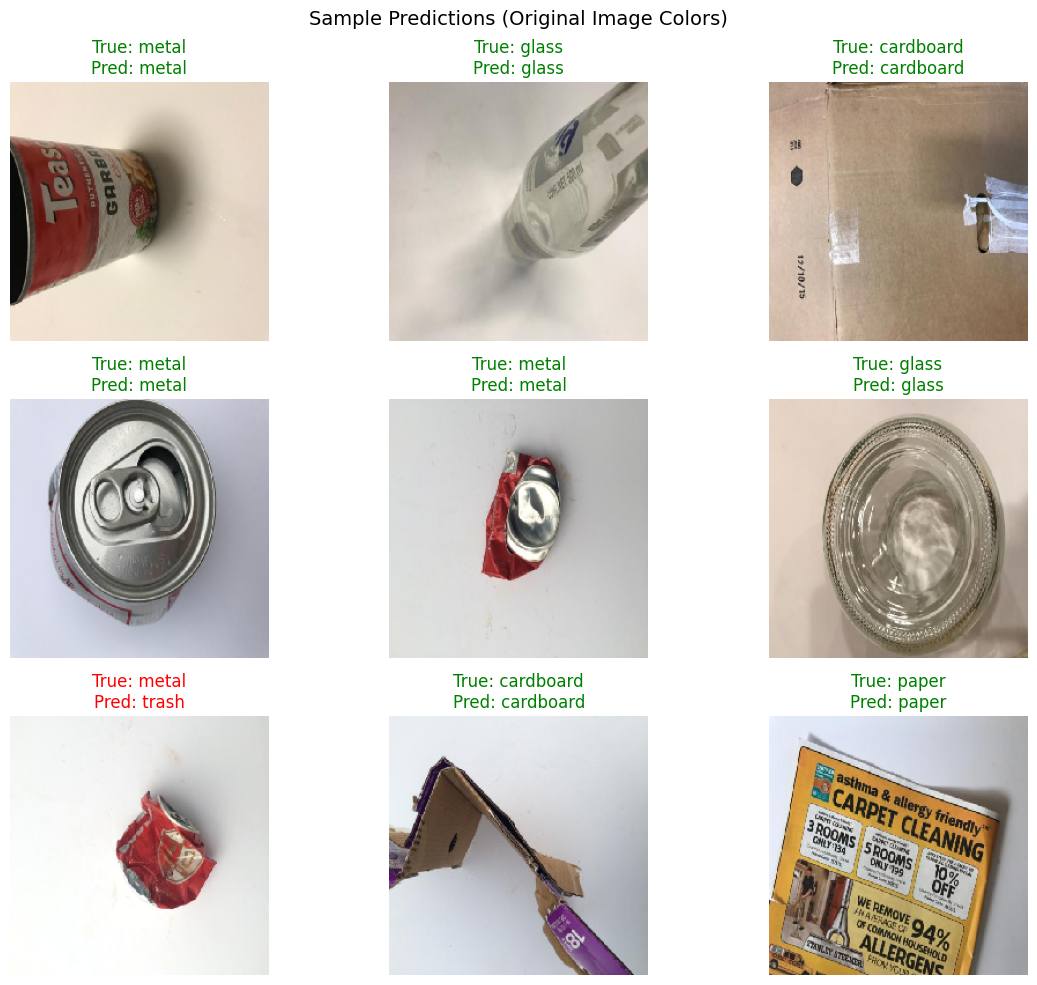

In [21]:
import numpy as np
import matplotlib.pyplot as plt
import random

batch_size = validation_generator.batch_size
num_images = len(validation_generator.classes)

sample_indices = random.sample(range(num_images), 9)

plt.figure(figsize=(12, 10))

for i, global_idx in enumerate(sample_indices):
    batch_idx = global_idx // batch_size
    img_idx = global_idx % batch_size

    images, _ = validation_generator[batch_idx]
    img = images[img_idx]

    # 🔄 Reverse ResNet preprocessing
    img_display = img.copy()
    img_display[..., 0] += 103.939
    img_display[..., 1] += 116.779
    img_display[..., 2] += 123.68
    img_display = img_display[..., ::-1]  # BGR → RGB
    img_display = np.clip(img_display, 0, 255).astype("uint8")

    true_label = class_names[y_true[global_idx]]
    pred_label = class_names[y_pred[global_idx]]
    color = "green" if true_label == pred_label else "red"

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_display)
    plt.title(f"True: {true_label}\nPred: {pred_label}", color=color)
    plt.axis("off")

plt.suptitle("Sample Predictions (Original Image Colors)", fontsize=14)
plt.tight_layout()
plt.show()

“Figure X shows sample predictions made by the ResNet50 model on the validation dataset. Green labels indicate correct predictions, while red labels represent misclassifications. The model correctly identifies most garbage categories, demonstrating strong visual feature learning.”

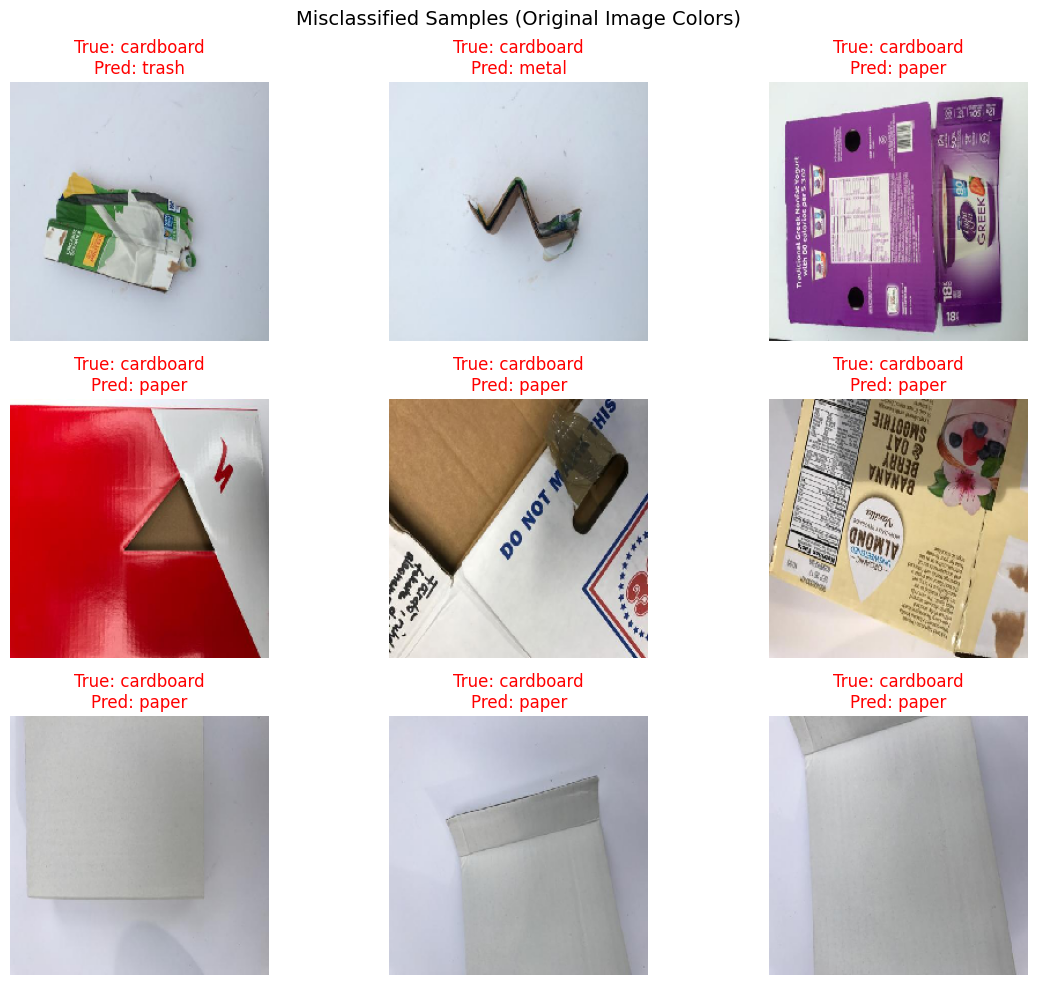

In [23]:
misclassified = np.where(y_true != y_pred)[0]

plt.figure(figsize=(12, 10))

for i, global_idx in enumerate(misclassified[:9]):
    batch_idx = global_idx // batch_size
    img_idx = global_idx % batch_size

    images, _ = validation_generator[batch_idx]
    img = images[img_idx]

    # 🔄 Reverse ResNet50 preprocessing
    img_display = img.copy()
    img_display[..., 0] += 103.939  # B
    img_display[..., 1] += 116.779  # G
    img_display[..., 2] += 123.68   # R
    img_display = img_display[..., ::-1]  # BGR → RGB
    img_display = np.clip(img_display, 0, 255).astype("uint8")

    plt.subplot(3, 3, i + 1)
    plt.imshow(img_display)
    plt.title(
        f"True: {class_names[y_true[global_idx]]}\nPred: {class_names[y_pred[global_idx]]}",
        color="red"
    )
    plt.axis("off")

plt.suptitle("Misclassified Samples (Original Image Colors)", fontsize=14)
plt.tight_layout()
plt.show()

In [24]:
import collections

counter = collections.Counter(train_generator.classes)
print(counter)

Counter({3: 594, 1: 501, 4: 482, 2: 410, 0: 403, 5: 137})
